# 11. Shor's Algorithm: Factoring 15

Shor's algorithm factors integers in polynomial time on a quantum computer, which is why it threatens RSA. The
quantum part is **order finding**: given $a$ coprime to $N$, find the smallest $r$ with $a^r \equiv 1 \pmod N$. This
notebook builds every piece for $N = 15$ (modular multiplication circuits, phase estimation with the QFT from
notebook 10, and continued fractions) and factors $15 = 3 \times 5$ on a simulator.

*Added after the course as an extension. The circuits live in `algorithms.py` and are tested in
`tests/test_algorithms.py`.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, Statevector
from qiskit_aer import AerSimulator

import algorithms as alg   # circuits shared with the test suite (tests/test_algorithms.py)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
from math import gcd

## From factoring to order finding

If $r$ is even and $a^{r/2} \not\equiv -1 \pmod N$, then $(a^{r/2}-1)(a^{r/2}+1) = a^r - 1$ is a multiple of $N$
while neither factor is, so $\gcd(a^{r/2} \pm 1, N)$ are non-trivial factors of $N$. The classical table below shows
which bases work for $N = 15$; the quantum computer's job is to find $r$ without this brute-force table.

In [2]:
N = 15
print(" a | order r | a^(r/2) mod 15 | gcd(a^(r/2)-1, 15) | gcd(a^(r/2)+1, 15)")
for a in range(2, N):
    if gcd(a, N) != 1:
        continue
    r = next(r for r in range(1, N) if pow(a, r, N) == 1)
    if r % 2 == 0:
        half = pow(a, r // 2, N)
        note = "  (a^(r/2) = -1: no factor)" if half == N - 1 else ""
        print(f"{a:2d} | {r:7d} | {half:14d} | {gcd(half - 1, N):18d} | {gcd(half + 1, N):18d}{note}")
    else:
        print(f"{a:2d} | {r:7d} | odd order: try another a")

 a | order r | a^(r/2) mod 15 | gcd(a^(r/2)-1, 15) | gcd(a^(r/2)+1, 15)
 2 |       4 |              4 |                  3 |                  5
 4 |       2 |              4 |                  3 |                  5
 7 |       4 |              4 |                  3 |                  5
 8 |       4 |              4 |                  3 |                  5
11 |       2 |             11 |                  5 |                  3
13 |       4 |              4 |                  3 |                  5
14 |       2 |             14 |                  1 |                 15  (a^(r/2) = -1: no factor)


## Modular multiplication as a quantum circuit

Order finding needs the unitary $U_a|y\rangle = |a y \bmod 15\rangle$ on 4 qubits. Because $2^4 = 16 \equiv 1 \pmod{15}$,
multiplying by 2 is a cyclic rotation of the four bits (three swaps). Multiplying by $15 - b$ equals multiplying by
$-b$, which complements all the bits (X gates). Every multiplier coprime to 15 is built this way. The check below
verifies all of them on every input $y = 1 \dots 14$.

In [3]:
for b in alg.MULTIPLIERS_MOD_15:
    U = alg.multiply_mod_15(b)
    ok = all(Statevector.from_int(y, 16).evolve(U).equiv(Statevector.from_int(b * y % 15, 16)) for y in range(1, 15))
    print(f"×{b:2d} mod 15: {'correct for all y' if ok else 'WRONG'}   ({U.size()} gates)")

print("\nCircuit for ×7 mod 15:")
print(alg.multiply_mod_15(7).draw())

× 1 mod 15: correct for all y   (0 gates)
× 2 mod 15: correct for all y   (3 gates)
× 4 mod 15: correct for all y   (6 gates)
× 7 mod 15: correct for all y   (13 gates)
× 8 mod 15: correct for all y   (9 gates)
×11 mod 15: correct for all y   (10 gates)
×13 mod 15: correct for all y   (7 gates)
×14 mod 15: correct for all y   (4 gates)

Circuit for ×7 mod 15:
                              ┌───┐
q_0: ───────X─────X────────X──┤ X ├
            │     │        │  ├───┤
q_1: ────X──X──X──X───X────X──┤ X ├
         │     │      │  ┌───┐└───┘
q_2: ─X──X──X──X──X───X──┤ X ├─────
      │     │     │ ┌───┐└───┘     
q_3: ─X─────X─────X─┤ X ├──────────
                    └───┘          


## The order-finding circuit (phase estimation)

$U_a$ has eigenvalues $e^{2\pi i s/r}$, so phase estimation on the state $|1\rangle$ (an equal superposition of
$U_a$'s eigenvectors) returns $s/r$ for a random $s$. With 8 counting qubits, the controlled powers $U_a^{2^j}$
multiply by $a^{2^j} \bmod 15$; those values are computed classically when the circuit is built, as in any
implementation of modular exponentiation. Here is the circuit for $a = 7$. Only two controlled multiplications
appear: $7^1 = 7$ and $7^2 = 49 \equiv 4$, while $7^4 \equiv 1 \pmod{15}$, so every higher power is the identity
and is left out. The inverse QFT from notebook 10 is drawn as one box.

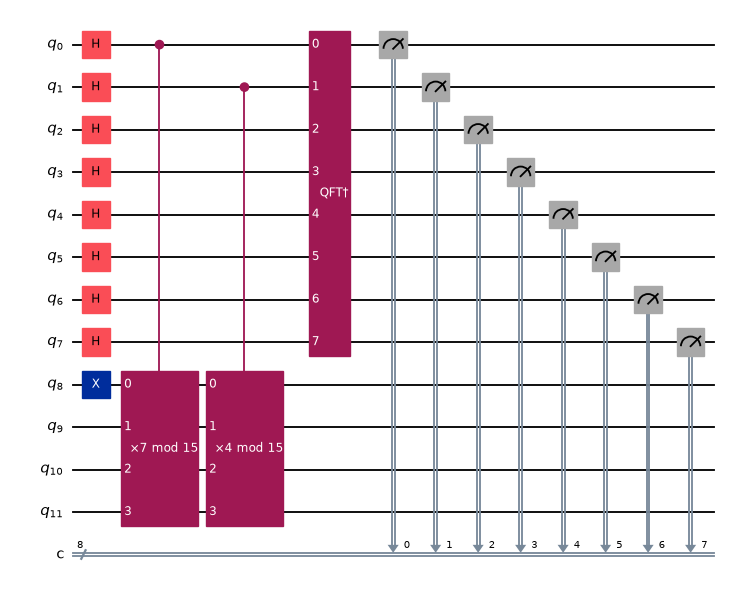

In [4]:
alg.order_finding_circuit(7).draw('mpl', fold=-1, scale=0.6)

## Running it for $a = 7$

The true order of 7 mod 15 is 4, so the measured 8-bit values should be multiples of $256/4 = 64$, i.e. phases
$0, \tfrac14, \tfrac12, \tfrac34$, each about 25% of the time.

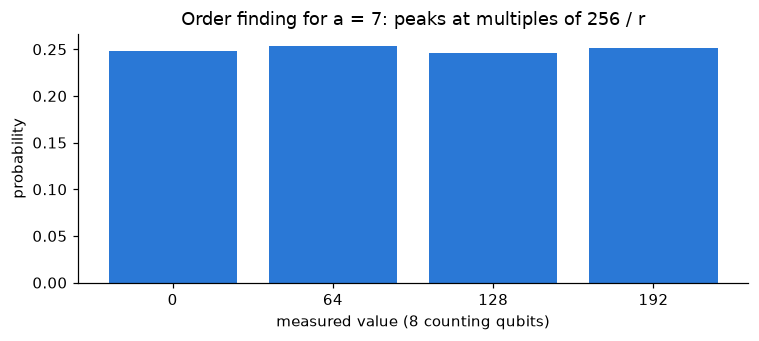

In [5]:
r, counts = alg.find_order(7, shots=2000, seed=7)
values = {int(k, 2): v for k, v in counts.items()}

plt.figure(figsize=(7, 3.2))
plt.bar([str(v) for v in sorted(values)], [values[v] / 2000 for v in sorted(values)], color="#2a78d6")
plt.xlabel("measured value (8 counting qubits)")
plt.ylabel("probability")
plt.title("Order finding for a = 7: peaks at multiples of 256 / r")
plt.tight_layout()
plt.show()

## From measurements to the order: continued fractions

Each measurement $m$ approximates $s/r$ as $m/256$. The continued-fraction expansion finds the closest fraction with
denominator at most $N$, whose denominator is a candidate for $r$. Outcomes with $s$ sharing a factor with $r$ give
only a divisor of $r$ (e.g. $128/256 = 1/2$), and $s = 0$ gives nothing, so the algorithm checks candidates
classically ($a^r \bmod 15 = 1$?) and keeps the smallest one that works.

In [6]:
from fractions import Fraction

print(" measured | phase m/256 | fraction | candidate r | 7^r mod 15")
for m in sorted(values):
    frac = Fraction(m, 256).limit_denominator(15)
    r_candidate = frac.denominator
    print(f"{m:9d} | {m / 256:11.4f} | {str(frac):8s} | {r_candidate:11d} | {pow(7, r_candidate, 15)}")
print(f"\nOrder found: r = {r}")

 measured | phase m/256 | fraction | candidate r | 7^r mod 15
        0 |      0.0000 | 0        |           1 | 7
       64 |      0.2500 | 1/4      |           4 | 1
      128 |      0.5000 | 1/2      |           2 | 4
      192 |      0.7500 | 3/4      |           4 | 1

Order found: r = 4


## Factoring 15 with every base

In [7]:
for a in range(2, 15):
    result = alg.shor_15(a, shots=128, seed=3)
    if gcd(a, 15) != 1:
        how = f"gcd({a}, 15) = {gcd(a, 15)}: the guess already shares a factor"
    elif result is None:
        how = "order is even but a^(r/2) = -1 mod 15: pick another a"
    else:
        r, _ = alg.find_order(a, shots=128, seed=3)
        how = f"order r = {r}, gcd({a}^{r // 2} ± 1, 15)"
    print(f"a = {a:2d}: {str(result):7s} {how}")

a =  2: (3, 5)  order r = 4, gcd(2^2 ± 1, 15)
a =  3: (3, 5)  gcd(3, 15) = 3: the guess already shares a factor


a =  4: (3, 5)  order r = 2, gcd(4^1 ± 1, 15)
a =  5: (3, 5)  gcd(5, 15) = 5: the guess already shares a factor
a =  6: (3, 5)  gcd(6, 15) = 3: the guess already shares a factor


a =  7: (3, 5)  order r = 4, gcd(7^2 ± 1, 15)


a =  8: (3, 5)  order r = 4, gcd(8^2 ± 1, 15)
a =  9: (3, 5)  gcd(9, 15) = 3: the guess already shares a factor
a = 10: (3, 5)  gcd(10, 15) = 5: the guess already shares a factor


a = 11: (3, 5)  order r = 2, gcd(11^1 ± 1, 15)
a = 12: (3, 5)  gcd(12, 15) = 3: the guess already shares a factor


a = 13: (3, 5)  order r = 4, gcd(13^2 ± 1, 15)


a = 14: None    order is even but a^(r/2) = -1 mod 15: pick another a


## Takeaways and limits

- Every base coprime to 15 except 14 factors 15 in one run. 14 ≡ −1 fails as predicted by the table, and a real
  implementation simply picks another random $a$.
- The circuit uses 12 qubits. Real implementations need about $2n$ to $3n$ logical qubits for an $n$-bit number, and
  the modular multipliers become the expensive part: breaking RSA-2048 is estimated to need on the order of a million
  noisy physical qubits, far beyond today's hardware.
- Precomputing $a^{2^j} \bmod N$ classically is standard, but for $N = 15$ it makes the circuit much simpler than in
  the general case, so this is a demonstration of the algorithm, not a benchmark.